In [1]:
from dotenv import load_dotenv
load_dotenv()

from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-5.4-mini", stream_usage=True,temperature=0.7)


In [2]:
from langchain_core.tools import tool
from langchain_tavily import TavilySearch

tavily = TavilySearch(max_results=3)

@tool
def tavily_search_tool(query: str) -> str:
    """Use this tool to search the web for the latest news and information."""
    return tavily.invoke(query)

In [3]:
tools=[tavily_search_tool]
llm_with_tools=llm.bind_tools(tools)

In [4]:
from typing import TypedDict, List
from langchain_core.prompts import ChatPromptTemplate


class graph_schema(TypedDict):
    messages:List

In [5]:
def llm_node(state:graph_schema)->graph_schema:
    
    messages= state['messages']
    
    prompt = ChatPromptTemplate(
    [
        ("system", "You must use the search tool for any question related to current events, news, or recent information."),
        ("human", "{input}"),
    ]
)
    
    chain=prompt|llm_with_tools

    response=chain.invoke({"input":messages})
    
    state["messages"]=messages + [response]

    return state

In [6]:
from langgraph.graph import StateGraph,START,END

def if_tool_call(state:graph_schema)-> str:
    last_message=state['messages'][-1]
    
    if last_message.tool_calls:
        return "tool_node"
    else:
        return "end"

In [7]:
from langgraph.prebuilt import ToolNode

tool_node = ToolNode(tools)

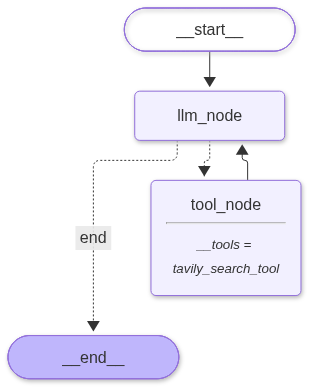

In [10]:
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

graph = StateGraph(graph_schema)

graph.add_node("llm_node", llm_node)
graph.add_node("tool_node", tool_node)  # ✅ using prebuilt

graph.add_edge(START, "llm_node")

graph.add_conditional_edges(
    "llm_node",
    if_tool_call,
    {
        "tool_node": "tool_node",
        "end": END
    }
)

graph.add_edge("tool_node", "llm_node")
graph.add_edge("llm_node", END)


ReAct_graph = graph.compile()
Image(ReAct_graph.get_graph().draw_mermaid_png())

In [11]:
from langchain_core.messages import HumanMessage

ReAct_graph.invoke({"messages": [HumanMessage(content="what is the latest news about hartal in Kerala today")]})

{'messages': [ToolMessage(content='{"query": "latest news about hartal in Kerala today", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://economictimes.indiatimes.com/topic/hartal", "title": "hartal: Latest News & Videos, Photos about hartal | The Economic Times - Page 1", "content": "Kerala Bandh Today April 28: A 12-hour statewide hartal is being observed in Kerala today, April 28, following the tragic death of dental student Nithin Raj. With over 50 organizations demanding justice, the protest has impacted public transport and commercial activity. Here is a breakdown of what to expect across the state.\\n\\nAfter High Court stricture, Kerala govt attaches properties of 248 PFI workers\\n\\n## After High Court stricture, Kerala govt attaches properties of 248 PFI workers [...] ## Kerala HC takes on suo motu case against PFI hartal\\n\\nSporadic incidents of violence, including stone pelting, were reported since Friday morning in various parts of

In [ ]:
for chunk in ReAct_graph.stream(
    {'messages':[HumanMessage(content='what is the uv index in kochi today')]},
    stream_mode='updates'
):
print(chunk)